# Walmart Weekly Sales Forecast

**Author:** Bryan Liranzo  |  **Tools:** Python, pandas, statsmodels, Prophet, matplotlib

## Executive summary

**Goal:** Predict Walmart's total weekly sales 12 weeks ahead so the business can plan inventory and staffing.

**Data:** 3 years of weekly sales (Feb 2010 to Oct 2012) for 45 stores, with holiday flags and economic indicators.

**Key results**
- The **Holt-Winters** model predicted weekly sales within **1.78%** on average, about **$821K** on a typical **$46M** week.
- That is **16% more accurate** than a simple "same week last year" forecast.
- **Holiday weeks bring 7.8% higher sales**, and the weeks before Christmas are the busiest of the year.
- Fuel price, CPI and unemployment have **little relationship** with sales.

## Contents
1. Setup
2. Load and clean the data
3. Explore the data
4. Build and compare forecasting models
5. Store-level forecasts
6. Conclusions and recommendations

## 1. Setup

In [1]:
import os
import logging
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from prophet import Prophet

# Hide routine library messages so the output stays readable
warnings.filterwarnings("ignore")
logging.getLogger("cmdstanpy").setLevel(logging.WARNING)
logging.getLogger("prophet").setLevel(logging.WARNING)

# Settings used throughout the notebook
DATA_PATH = "Walmart.csv"   # path to the Kaggle CSV
HORIZON = 12                # weeks to forecast
SEASON_LENGTH = 52          # weeks in a year
IMAGE_DIR = "images"        # where charts are saved

os.makedirs(IMAGE_DIR, exist_ok=True)
sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.figsize": (12, 5), "axes.titlesize": 14, "axes.titleweight": "bold"})

C:\Users\bryan\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Importing plotly failed. Interactive plots will not work.


In [2]:
# Helper functions

def save_chart(filename):
    """Tidy the layout, save the current chart to the images folder, and show it."""
    plt.tight_layout()
    plt.savefig(os.path.join(IMAGE_DIR, filename), dpi=150)
    plt.show()


def in_millions(values):
    """Convert dollar values to millions for easier-to-read charts."""
    return values / 1_000_000


def score_forecast(actual, predicted):
    """Return the three accuracy measures used to compare models."""
    errors = actual.values - np.asarray(predicted)
    return {
        "MAE ($)": np.abs(errors).mean(),                         # average miss in dollars
        "RMSE ($)": np.sqrt((errors ** 2).mean()),                # penalizes big misses more
        "MAPE (%)": (np.abs(errors) / actual.values).mean() * 100 # average miss as a percent
    }

## 2. Load and clean the data

Each row is one store's sales for one week. The checks below confirm the data is complete before any analysis.

In [3]:
sales = pd.read_csv(DATA_PATH)

# Dates are stored as day-month-year (05-02-2010 is 5 February 2010)
sales["Date"] = pd.to_datetime(sales["Date"], dayfirst=True)
sales = sales.sort_values(["Store", "Date"]).reset_index(drop=True)

print(f"Rows:            {len(sales):,}")
print(f"Stores:          {sales['Store'].nunique()}")
print(f"Weeks:           {sales['Date'].nunique()}")
print(f"Date range:      {sales['Date'].min():%b %d, %Y} to {sales['Date'].max():%b %d, %Y}")
print(f"Missing values:  {sales.isna().sum().sum()}")
print(f"Duplicate rows:  {sales.duplicated().sum()}")

sales.head()

Rows:            6,435
Stores:          45
Weeks:           143
Date range:      Feb 05, 2010 to Oct 26, 2012
Missing values:  0
Duplicate rows:  0


,Store,Date,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment
0,1,2010-02-05,1643690.90,0,42.31,2.572,211.096358,8.106
1,1,2010-02-12,1641957.44,1,38.51,2.548,211.242170,8.106
2,1,2010-02-19,1611968.17,0,39.93,2.514,211.289143,8.106
3,1,2010-02-26,1409727.59,0,46.63,2.561,211.319643,8.106
4,1,2010-03-05,1554806.68,0,46.50,2.625,211.350143,8.106


In [4]:
# Calendar columns used in the analysis
sales["Year"] = sales["Date"].dt.year
sales["Week"] = sales["Date"].dt.isocalendar().week.astype(int)

# Total sales across all 45 stores for each week: the series we forecast
weekly_total = sales.groupby("Date")["Weekly_Sales"].sum().asfreq("W-FRI")

print(f"Weeks with missing totals: {weekly_total.isna().sum()}")
print(f"Average weekly sales:      ${weekly_total.mean():,.0f}")

Weeks with missing totals: 0
Average weekly sales:      $47,113,419


**Result:** The data is clean, with no missing values, duplicates or gaps in the weekly timeline.

## 3. Explore the data

### 3.1 Overall trend

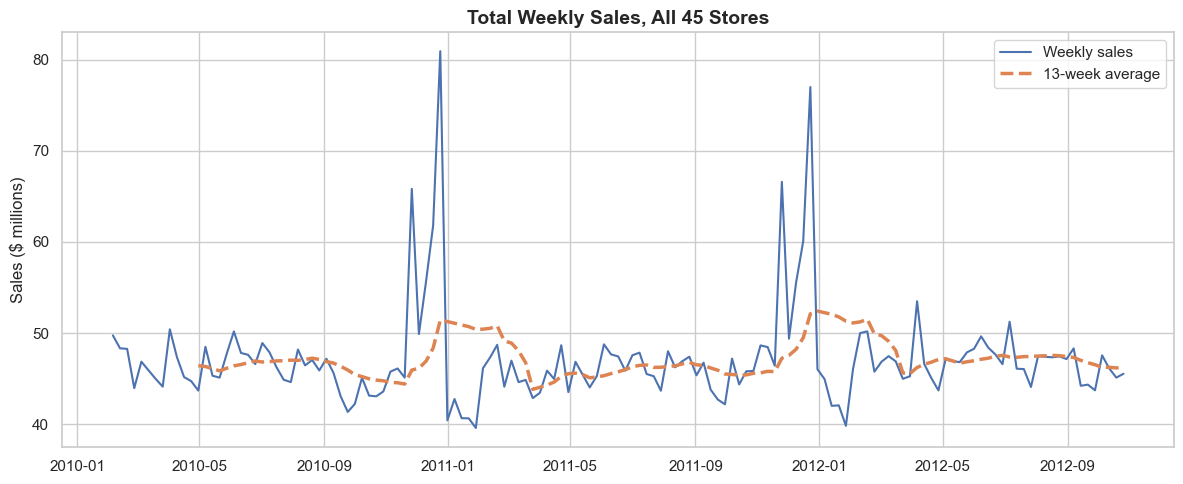

Average weekly sales by year:
  2010: $47.7M
  2011: $47.1M
  2012: $46.5M


In [5]:
fig, ax = plt.subplots()
ax.plot(weekly_total.index, in_millions(weekly_total), label="Weekly sales", linewidth=1.5)
ax.plot(weekly_total.index, in_millions(weekly_total.rolling(13).mean()),
        label="13-week average", linewidth=2.5, linestyle="--")
ax.set(title="Total Weekly Sales, All 45 Stores", ylabel="Sales ($ millions)", xlabel="")
ax.legend()
save_chart("01_total_sales.png")

weeks_per_year = sales.groupby("Year")["Date"].nunique()
avg_by_year = sales.groupby("Year")["Weekly_Sales"].sum() / weeks_per_year
print("Average weekly sales by year:")
for year, value in avg_by_year.items():
    print(f"  {year}: ${value / 1e6:,.1f}M")

**Finding:** Sales are steady from year to year, with sharp spikes at the end of each year.

### 3.2 Seasonal pattern

Seasonal decomposition splits sales into a long-term **trend**, a repeating yearly **seasonal** pattern, and leftover random **noise**.

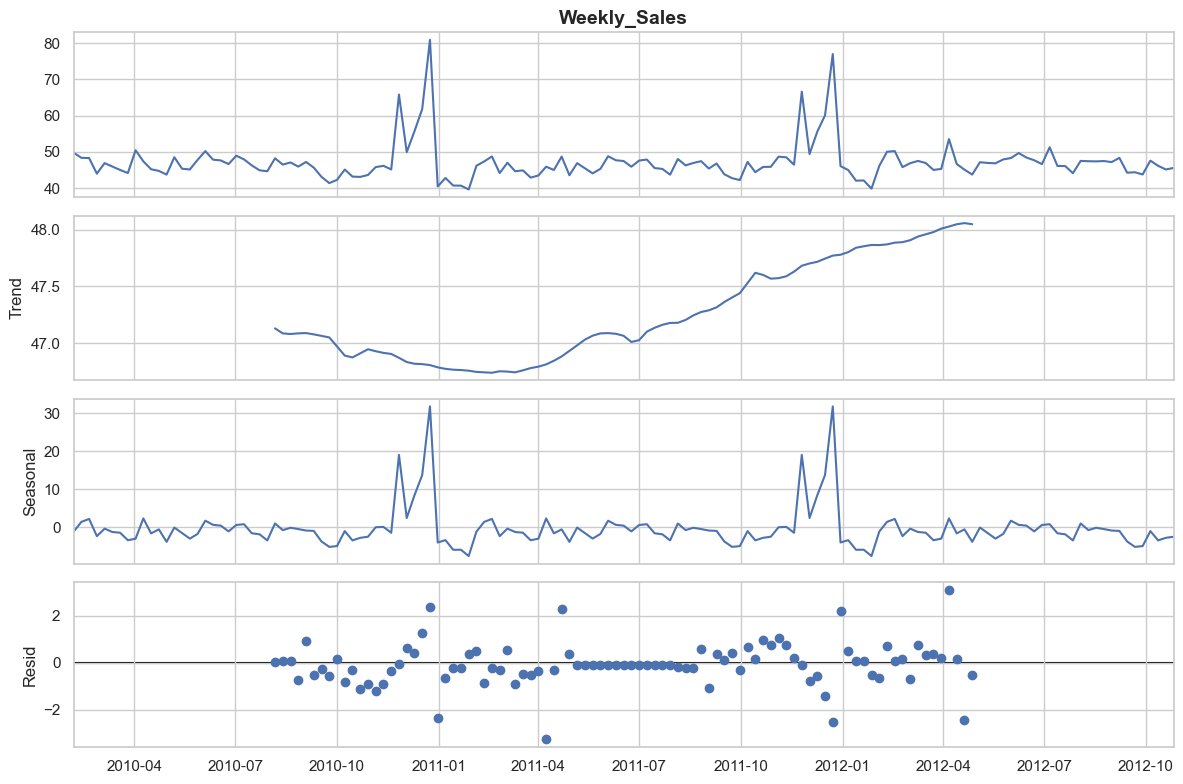

In [17]:
decomposition = seasonal_decompose(in_millions(weekly_total), model="additive", period=SEASON_LENGTH)
fig = decomposition.plot()
fig.set_size_inches(12, 8)
save_chart("02_decomposition.png")

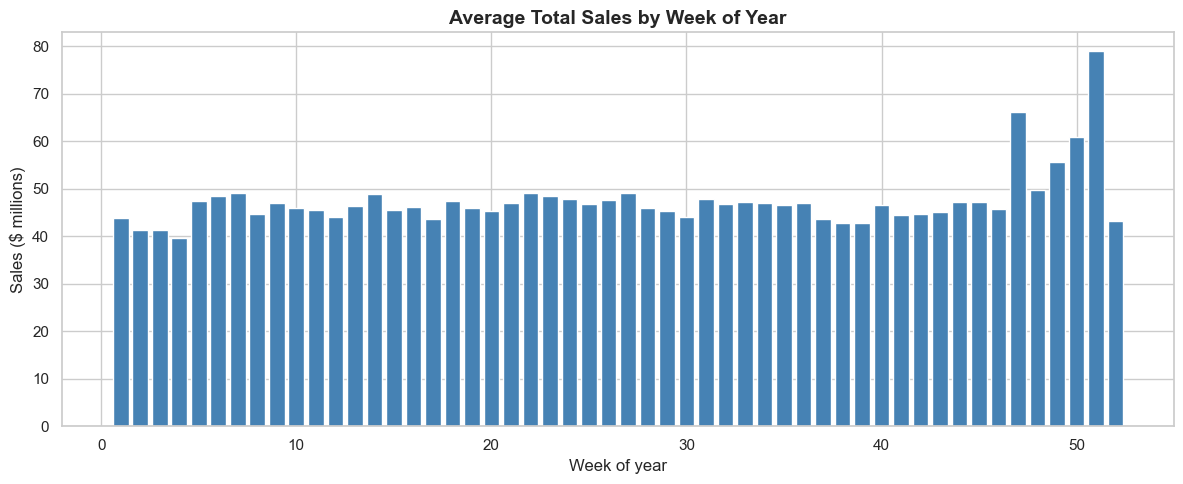

Five busiest weeks of the year:
  Week 51: $79.0M
  Week 47: $66.2M
  Week 50: $61.0M
  Week 49: $55.6M
  Week 48: $49.6M


In [7]:
avg_by_week = (sales.groupby("Week")["Weekly_Sales"].sum()
               / sales.groupby("Week")["Date"].nunique())

fig, ax = plt.subplots()
ax.bar(avg_by_week.index, in_millions(avg_by_week), color="steelblue")
ax.set(title="Average Total Sales by Week of Year", ylabel="Sales ($ millions)", xlabel="Week of year")
save_chart("03_week_of_year.png")

print("Five busiest weeks of the year:")
for week, value in avg_by_week.nlargest(5).items():
    print(f"  Week {week}: ${value / 1e6:,.1f}M")

**Finding:** The yearly pattern is strong and repeats. Thanksgiving (week 47) and the weeks before Christmas (weeks 50 and 51) are the busiest of the year.

### 3.3 Holiday impact

In [8]:
holiday_weeks = sales.groupby(["Date", "Holiday_Flag"])["Weekly_Sales"].sum().reset_index()
holiday_avg = holiday_weeks.loc[holiday_weeks["Holiday_Flag"] == 1, "Weekly_Sales"].mean()
regular_avg = holiday_weeks.loc[holiday_weeks["Holiday_Flag"] == 0, "Weekly_Sales"].mean()
holiday_lift = (holiday_avg / regular_avg - 1) * 100

print(f"Average holiday week:  ${holiday_avg / 1e6:,.1f}M")
print(f"Average regular week:  ${regular_avg / 1e6:,.1f}M")
print(f"Holiday lift:          {holiday_lift:+.1f}%")

Average holiday week:  $50.5M
Average regular week:  $46.9M
Holiday lift:          +7.8%


**Finding:** Holiday weeks average **7.8% higher** sales than regular weeks.

*Note:* The dataset flags Super Bowl, Labor Day, Thanksgiving and Christmas weeks. The biggest Christmas spike falls in the week *before* the flagged week, so the true holiday-season effect is larger than this average suggests.

### 3.4 Store performance

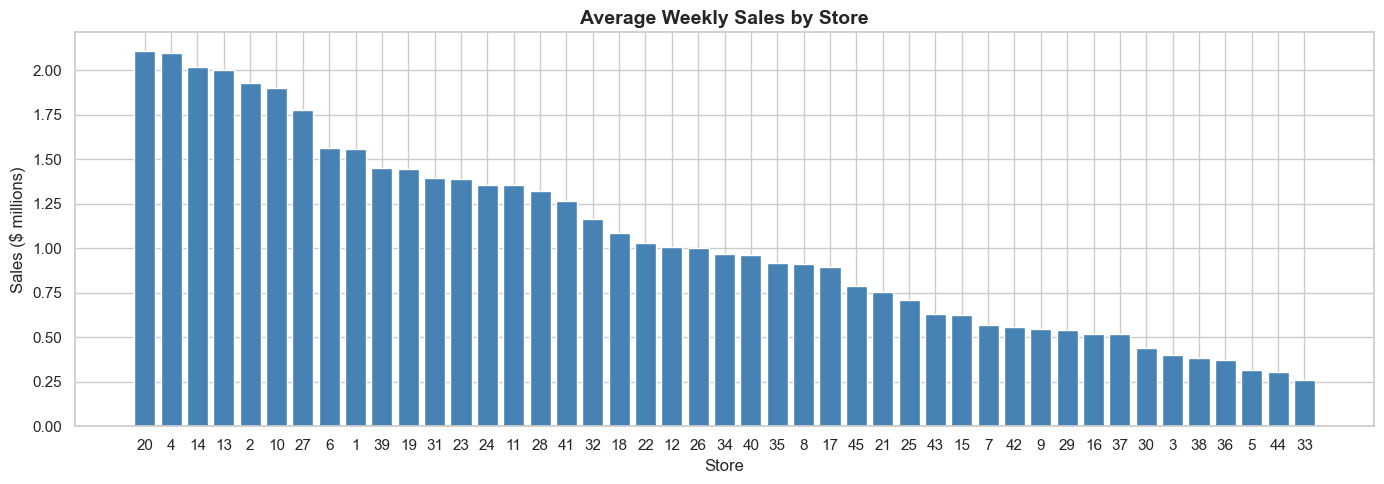

Top 5 stores by sales


,avg_sales,volatility_%
Store,,
20,"$2,107,677",13.1%
4,"$2,094,713",12.7%
14,"$2,020,978",15.7%
13,"$2,003,620",13.3%
2,"$1,925,751",12.3%


Bottom 5 stores by sales


,avg_sales,volatility_%
Store,,
38,"$385,732",11.1%
36,"$373,512",16.3%
5,"$318,012",11.9%
44,"$302,749",8.2%
33,"$259,862",9.3%


Most volatile stores


,avg_sales,volatility_%
Store,,
35,"$919,725",23.0%
7,"$570,617",19.7%
15,"$623,312",19.3%
29,"$539,451",18.4%
23,"$1,389,864",18.0%


In [9]:
store_summary = (sales.groupby("Store")["Weekly_Sales"]
                 .agg(avg_sales="mean", std_sales="std")
                 .sort_values("avg_sales", ascending=False))

# Volatility: how much a store's sales swing relative to its size
store_summary["volatility_%"] = store_summary["std_sales"] / store_summary["avg_sales"] * 100

fig, ax = plt.subplots(figsize=(14, 5))
ax.bar(store_summary.index.astype(str), in_millions(store_summary["avg_sales"]), color="steelblue")
ax.set(title="Average Weekly Sales by Store", ylabel="Sales ($ millions)", xlabel="Store")
save_chart("04_store_sales.png")

table_format = {"avg_sales": "${:,.0f}", "volatility_%": "{:.1f}%"}
columns = ["avg_sales", "volatility_%"]
print("Top 5 stores by sales")
display(store_summary.head(5)[columns].style.format(table_format))
print("Bottom 5 stores by sales")
display(store_summary.tail(5)[columns].style.format(table_format))
print("Most volatile stores")
display(store_summary.nlargest(5, "volatility_%")[columns].style.format(table_format))

**Finding:** Store sizes vary widely, and a handful of stores swing much more week to week than the rest. Those stores carry the most risk of running out of stock or overstaffing.

### 3.5 Economic factors

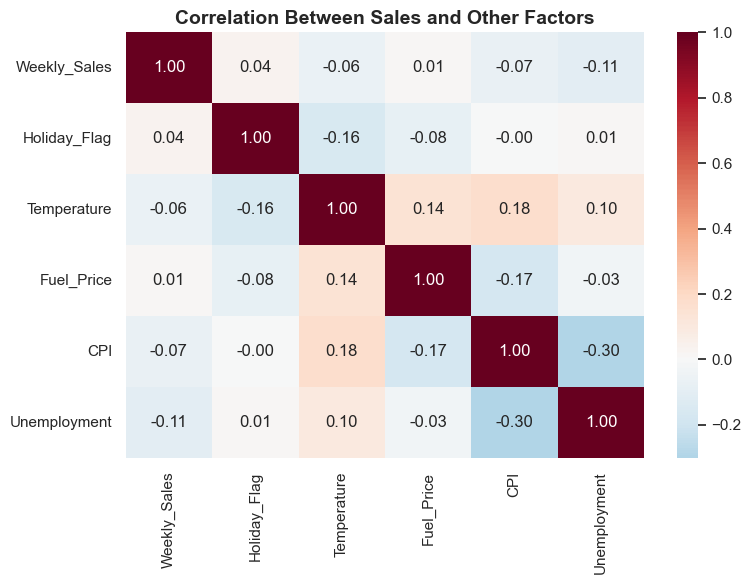

In [10]:
factors = ["Weekly_Sales", "Holiday_Flag", "Temperature", "Fuel_Price", "CPI", "Unemployment"]

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(sales[factors].corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax)
ax.set_title("Correlation Between Sales and Other Factors")
save_chart("05_correlations.png")

**Finding:** Temperature, fuel price, CPI and unemployment have weak relationships with sales. Seasonality and store size drive sales far more than these economic indicators, so the forecasting models below rely on past sales patterns alone.

## 4. Build and compare forecasting models

**Method:** Hold back the most recent 12 weeks, train each model on everything before them, then compare each model's forecast with what actually happened. The data is split by date, never shuffled, so models only learn from the past.

**Models tested**

| Model | How it works |
|---|---|
| Seasonal naive (baseline) | Next week's sales = the same week last year |
| Moving average | Average of the last 4 weeks, repeated forward |
| Holt-Winters | Learns the level, trend and yearly pattern of sales |
| Prophet | Meta's forecasting library, with holidays built in |

**Accuracy measures:** MAE (average miss in dollars), RMSE (like MAE, but penalizes large misses more) and MAPE (average miss as a percentage).

In [11]:
train = weekly_total.iloc[:-HORIZON]
test = weekly_total.iloc[-HORIZON:]

print(f"Training data: {train.index.min():%b %d, %Y} to {train.index.max():%b %d, %Y} ({len(train)} weeks)")
print(f"Test data:     {test.index.min():%b %d, %Y} to {test.index.max():%b %d, %Y} ({len(test)} weeks)")

Training data: Feb 05, 2010 to Aug 03, 2012 (131 weeks)
Test data:     Aug 10, 2012 to Oct 26, 2012 (12 weeks)


In [12]:
def seasonal_naive_forecast(history, horizon):
    """Repeat the sales from the same weeks one year earlier."""
    return history.iloc[-SEASON_LENGTH:-SEASON_LENGTH + horizon].values


def moving_average_forecast(history, horizon, window=4):
    """Repeat the average of the most recent weeks."""
    return np.repeat(history.iloc[-window:].mean(), horizon)


def holt_winters_forecast(history, horizon):
    """Exponential smoothing with a damped trend and a yearly seasonal pattern."""
    model = ExponentialSmoothing(history, trend="add", damped_trend=True,
                                 seasonal="add", seasonal_periods=SEASON_LENGTH).fit()
    return model.forecast(horizon).values


def build_holiday_calendar():
    """Holiday dates for Prophet: the dataset's flagged weeks plus the Thanksgiving and Christmas seasons."""
    flagged = pd.DataFrame({"holiday": "flagged_holiday",
                            "ds": sales.loc[sales["Holiday_Flag"] == 1, "Date"].unique()})
    thanksgiving = pd.DataFrame({"holiday": "thanksgiving",
                                 "ds": pd.to_datetime(["2010-11-26", "2011-11-25", "2012-11-23"]),
                                 "lower_window": 0, "upper_window": 7})
    christmas = pd.DataFrame({"holiday": "christmas",
                              "ds": pd.to_datetime(["2010-12-24", "2011-12-23", "2012-12-21"]),
                              "lower_window": -7, "upper_window": 0})
    return pd.concat([flagged, thanksgiving, christmas]).fillna(0)


def prophet_forecast(history, horizon):
    """Prophet with yearly seasonality and holiday effects."""
    model = Prophet(yearly_seasonality=True, weekly_seasonality=False,
                    daily_seasonality=False, holidays=build_holiday_calendar())
    model.fit(pd.DataFrame({"ds": history.index, "y": history.values}))
    future_dates = pd.DataFrame({"ds": pd.date_range(history.index[-1], periods=horizon + 1, freq="W-FRI")[1:]})
    return model.predict(future_dates)["yhat"].values

In [13]:
models = {
    "Seasonal naive (baseline)": seasonal_naive_forecast,
    "Moving average": moving_average_forecast,
    "Holt-Winters": holt_winters_forecast,
    "Prophet": prophet_forecast,
}

forecasts = {}
scores = []
for name, forecast_function in models.items():
    forecasts[name] = forecast_function(train, HORIZON)
    scores.append({"Model": name, **score_forecast(test, forecasts[name])})

results = pd.DataFrame(scores).set_index("Model").sort_values("MAPE (%)")
baseline_mape = results.loc["Seasonal naive (baseline)", "MAPE (%)"]
results["Improvement vs baseline"] = (baseline_mape - results["MAPE (%)"]) / baseline_mape * 100
results.to_csv("model_results.csv")

results.style.format({"MAE ($)": "${:,.0f}", "RMSE ($)": "${:,.0f}",
                      "MAPE (%)": "{:.2f}%", "Improvement vs baseline": "{:+.1f}%"})

15:20:35 - cmdstanpy - INFO - Chain [1] start processing
15:20:35 - cmdstanpy - INFO - Chain [1] done processing


,MAE ($),RMSE ($),MAPE (%),Improvement vs baseline
Model,,,,
Holt-Winters,"$821,489","$1,009,629",1.78%,+16.1%
Seasonal naive (baseline),"$974,642","$1,160,987",2.12%,+0.0%
Prophet,"$1,204,324","$1,396,666",2.59%,-22.3%
Moving average,"$1,378,075","$1,512,787",2.98%,-40.9%


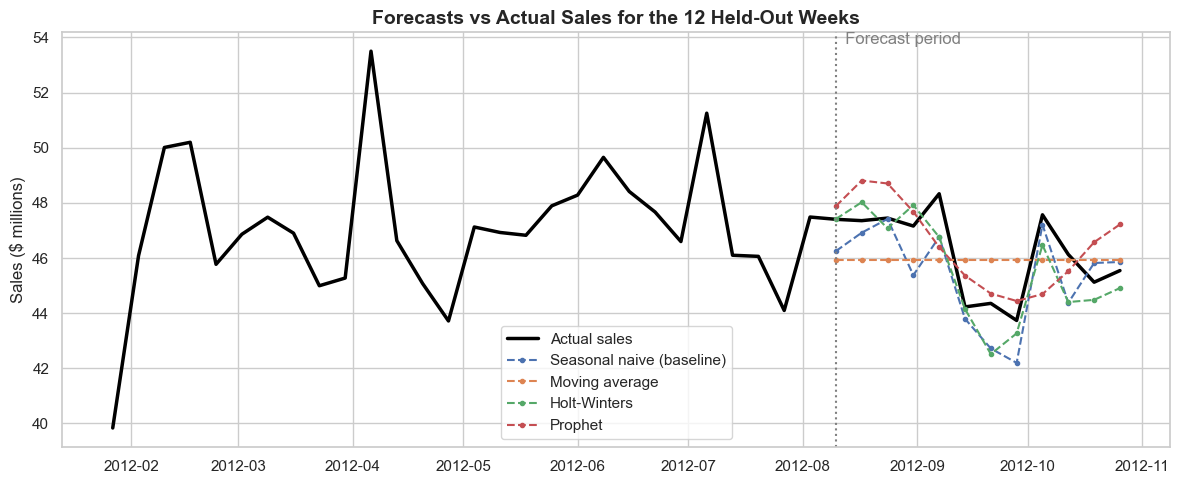

In [14]:
recent_weeks = weekly_total.iloc[-40:]

fig, ax = plt.subplots()
ax.plot(recent_weeks.index, in_millions(recent_weeks), color="black", linewidth=2.5, label="Actual sales")
for name, predicted in forecasts.items():
    ax.plot(test.index, in_millions(predicted), linestyle="--", marker="o", markersize=3, label=name)
ax.axvline(test.index[0], color="gray", linestyle=":")
ax.text(test.index[0], ax.get_ylim()[1], "  Forecast period", va="top", color="gray")
ax.set(title="Forecasts vs Actual Sales for the 12 Held-Out Weeks", ylabel="Sales ($ millions)", xlabel="")
ax.legend()
save_chart("06_forecast_vs_actual.png")

In [15]:
best_model = results.index[0]
best = results.loc[best_model]

print("RESULTS SUMMARY")
print(f"Best model:              {best_model}")
print(f"Average error (MAPE):    {best['MAPE (%)']:.2f}%")
print(f"Baseline error (MAPE):   {baseline_mape:.2f}%")
print(f"Improvement vs baseline: {best['Improvement vs baseline']:.1f}%")
print(f"Average weekly miss:     ${best['MAE ($)']:,.0f} on ~${test.mean():,.0f} of weekly sales")

RESULTS SUMMARY
Best model:              Holt-Winters
Average error (MAPE):    1.78%
Baseline error (MAPE):   2.12%
Improvement vs baseline: 16.1%
Average weekly miss:     $821,489 on ~$46,197,674 of weekly sales


**Finding:** Holt-Winters was the most accurate model, missing by **1.78%** per week on average, **16% better** than the baseline.

**Why Holt-Winters beat Prophet:** Walmart's sales follow a strong, stable yearly pattern, which Holt-Winters is designed to capture. With under three years of history, Prophet's extra flexibility did not improve accuracy.

## 5. Store-level forecasts

Planning happens store by store, so this section tests Holt-Winters on the five largest stores individually.

In [16]:
store_scores = []
for store in store_summary.head(5).index:
    store_sales = sales[sales["Store"] == store].set_index("Date")["Weekly_Sales"].asfreq("W-FRI")
    store_train, store_test = store_sales.iloc[:-HORIZON], store_sales.iloc[-HORIZON:]
    store_scores.append({
        "Store": store,
        "Baseline MAPE (%)": score_forecast(store_test, seasonal_naive_forecast(store_train, HORIZON))["MAPE (%)"],
        "Holt-Winters MAPE (%)": score_forecast(store_test, holt_winters_forecast(store_train, HORIZON))["MAPE (%)"],
    })

pd.DataFrame(store_scores).set_index("Store").style.format("{:.2f}%")

,Baseline MAPE (%),Holt-Winters MAPE (%)
Store,,
20,4.01%,2.40%
4,2.94%,1.94%
14,19.96%,7.37%
13,3.75%,2.18%
2,5.57%,2.81%


**Finding:** Individual stores are harder to forecast than the company total, because store-level ups and downs partly cancel out when added together. Errors are higher here, which is expected.

## 6. Conclusions and Recommendations

1. **Use the Holt-Winters model to plan inventory and staffing 12 weeks ahead.** Its predictions are off by only about 1.8% a week, roughly $821K out of a typical $46M week. That is 16% more accurate than simply copying last year's sales.
2. **Add staff and stock from late November through December.** Holiday weeks bring in 7.8% more sales than regular weeks, and the weeks right before Christmas are the busiest of the year.
3. **Keep extra backup inventory at stores with unpredictable sales** (see section 3.4). Their sales go up and down the most from week to week, so they are the most likely to run out of stock.
4. **Don't plan around gas prices, inflation (CPI) or unemployment.** These had almost no effect on sales.

### Limitations
- Less than three years of data means the model has seen only two full holiday seasons.
- The 12-week test period (August to October 2012) does not include the holiday peak.